# 17 - Hybrid Recommendation System (MovieLens 100K)
**Topic:** Recommendation Systems  |  **Reference:** "Hybrid Recommendation System using Python" (amanxai.com, Jun 2023)

**Question.** Which movies should we suggest to a user, and does mixing collaborative filtering (people who liked what you liked) with content (genres) beat each alone?

**Reference method:** a fashion-products table; content-based filtering with TF-IDF text similarity, collaborative filtering with `surprise` SVD to predict ratings, and a weighted blend; no hold-out evaluation. (The `surprise` package does not install on this machine's Python version, and the fashion file's ratings cannot be validated, so I use the standard **MovieLens 100K** data: 100,000 real ratings by 943 users on 1,682 films.)
**What I do:** a proper **time-based hold-out** (every user's last 20% of ratings is hidden), **ranking metrics** (Recall@10, NDCG@10, hit rate), five recommenders (popularity, content, item-kNN, SVD, hybrid), the **blend weights tuned on a separate validation slice**, plus coverage, novelty, diversity, **cold-start items** and **new users**, and a check that a lower rating-prediction error (RMSE) is not the same as a better top-10 list.

## 1. Libraries and data

In [1]:
import warnings, os, json, joblib, time
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import sparse
from sklearn.decomposition import TruncatedSVD
sns.set_theme(style="whitegrid", context="notebook")
np.random.seed(0); os.makedirs("model", exist_ok=True)
r = pd.read_csv("../_data/ml100k/u.data", sep="\t", names=["u", "i", "r", "t"]); r["u"] -= 1; r["i"] -= 1
gen = pd.read_csv("../_data/ml100k/u.genre", sep="|", header=None)[0].tolist()
it = pd.read_csv("../_data/ml100k/u.item", sep="|", header=None, encoding="latin-1"); it.columns = ["id", "title", "date", "vdate", "url"] + gen
it["year"] = pd.to_datetime(it.date, errors="coerce").dt.year; nU, nI = r.u.nunique(), len(it)
print(len(r), "ratings |", nU, "users |", nI, "movies | density %.1f%%" % (len(r) / (nU * nI) * 100)); r.head(3)

100000 ratings | 943 users | 1682 movies | density 6.3%


,u,i,r,t
0,195,241,3,881250949
1,185,301,3,891717742
2,21,376,1,878887116


## 2. Look at the data first

ratings per user: min 20, median 65, max 737 | ratings per movie: median 27, max 583, movies with <=5 ratings: 384 (23%)
the most popular 10% of movies receive 43% of all ratings


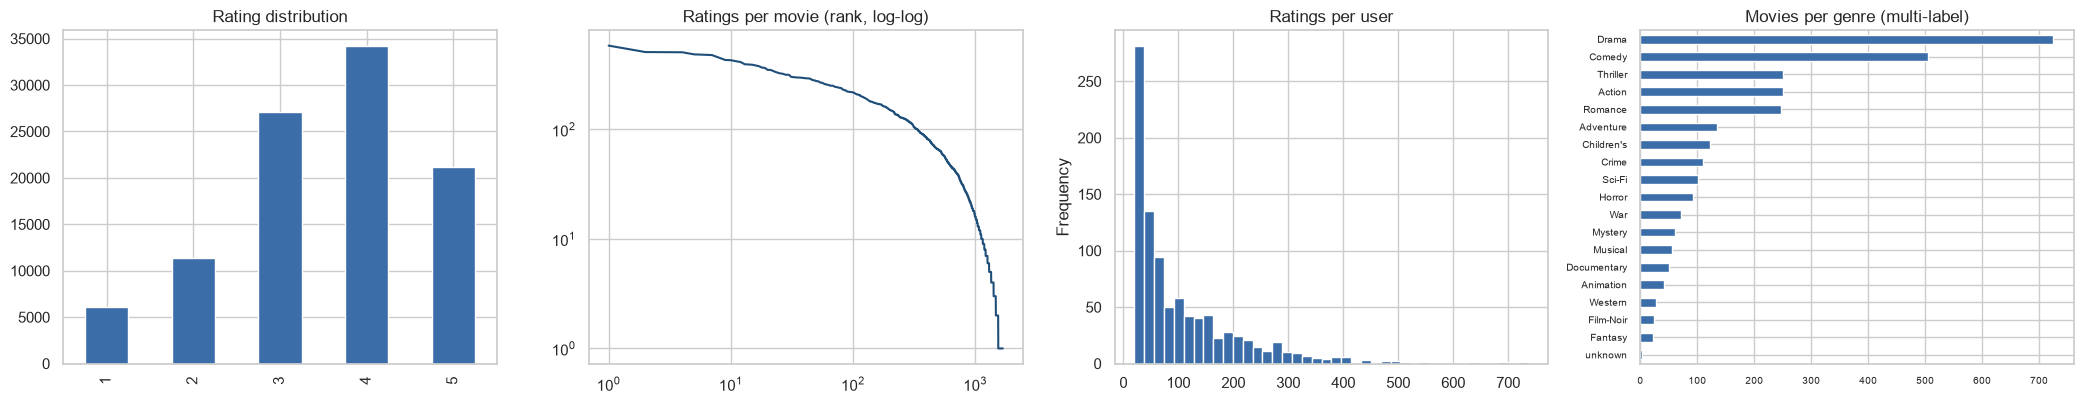

In [2]:
pop = r.groupby("i").size().sort_values(ascending=False); act = r.groupby("u").size()
print("ratings per user: min %d, median %d, max %d | ratings per movie: median %d, max %d, movies with <=5 ratings: %d (%.0f%%)" % (act.min(), act.median(), act.max(), pop.median(), pop.max(), (pop <= 5).sum() + (nI - len(pop)), ((pop <= 5).sum() + (nI - len(pop))) / nI * 100))
top10 = pop.iloc[: int(.1 * nI)].sum() / len(r); print("the most popular 10%% of movies receive %.0f%% of all ratings" % (top10 * 100))
fig, ax = plt.subplots(1, 4, figsize=(21, 4.2))
r.r.value_counts().sort_index().plot.bar(ax=ax[0], color="#3b6ea8"); ax[0].set_title("Rating distribution"); ax[0].set_xlabel("")
ax[1].plot(np.arange(1, len(pop) + 1), pop.values, color="#1f4e79"); ax[1].set_xscale("log"); ax[1].set_yscale("log"); ax[1].set_title("Ratings per movie (rank, log-log)")
act.plot.hist(bins=40, ax=ax[2], color="#3b6ea8"); ax[2].set_title("Ratings per user")
it[gen].sum().sort_values().plot.barh(ax=ax[3], color="#3b6ea8"); ax[3].set_title("Movies per genre (multi-label)"); ax[3].tick_params(labelsize=7)
plt.tight_layout(); plt.show()

**Reading it.** 943 users, 1,682 movies, 100,000 ratings: only **6.3% of the user-movie grid is filled**. Every user has at least 20 ratings (median 65, up to 737). Ratings lean positive: 55% are 4 or 5 and the mean is 3.53. Attention is concentrated: the most popular 10% of movies get **43% of all ratings**, while 384 movies (23%) have five ratings or fewer. That concentration means a "recommend popular things" strategy is a real competitor and that many movies are *cold* (almost no data).

## 3. Time-based split and the evaluation protocol
For every user, ratings are sorted by time: the **first 80% are training, the last 20% are the test**. For a final model-selection slice, the last 15% of each user's *training* ratings are a **validation** set (weights are tuned there, never on the test). A movie is **relevant** if the user rated it **4 or 5**. For each user the recommender ranks all movies the user has not rated in the training period; we look at the top 10.

In [3]:
r = r.sort_values(["u", "t"]).reset_index(drop=True); r["rank"] = r.groupby("u").cumcount(); r["n"] = r.groupby("u")["rank"].transform("size")
def split(df, frac): return df[df["rank"] < (df.n * frac).astype(int)], df[df["rank"] >= (df.n * frac).astype(int)]
train, test = split(r, .8)
tr_core = train.copy(); tr_core["rank"] = tr_core.groupby("u").cumcount(); tr_core["n"] = tr_core.groupby("u")["rank"].transform("size"); fit_core, val = split(tr_core, .85)
print("train %d | validation (inside train) %d | test %d ratings" % (len(train), len(val), len(test)))
def mats(df):
    pos = df[df.r >= 4]; P = sparse.csr_matrix((np.ones(len(pos)), (pos.u, pos.i)), shape=(nU, nI)); S = sparse.csr_matrix((np.ones(len(df)), (df.u, df.i)), shape=(nU, nI)); return P, S
def relevant(df):
    d = df[df.r >= 4]; return {u: set(g.i) for u, g in d.groupby("u")}
def evaluate(Sc, seen, rel, k=10, items_mask=None):
    Sc = Sc.copy(); Sc[seen.toarray() > 0] = -np.inf
    if items_mask is not None: Sc[:, ~items_mask] = -np.inf
    top = np.argpartition(-Sc, k, axis=1)[:, :k]; order = np.take_along_axis(Sc, top, 1).argsort(1)[:, ::-1]; top = np.take_along_axis(top, order, 1)
    rec, ndcg, hit, users = [], [], [], []
    disc = 1 / np.log2(np.arange(2, k + 2))
    for u in range(nU):
        rs = rel.get(u)
        if not rs: continue
        h = np.array([i in rs for i in top[u]]); rec.append(h.sum() / min(len(rs), k)); hit.append(h.any()); ndcg.append((h * disc).sum() / disc[: min(len(rs), k)].sum()); users.append(u)
    evaluate.last = (np.array(users), np.array(ndcg))
    return {"recall@10": np.mean(rec), "ndcg@10": np.mean(ndcg), "hit@10": np.mean(hit)}, top

train 79619 | validation (inside train) 12360 | test 20381 ratings


## 4. Five recommenders
* **Popularity:** the same list for everybody (most liked movies in training).
* **Content-based:** each movie is a vector of its 19 genres plus decade; a user's profile is the mean vector of movies they liked; score = cosine similarity.
* **Item-kNN:** movies similar (cosine) in *who liked them* to movies the user liked.
* **SVD (PureSVD):** low-rank factorisation (40 factors) of the user-by-movie "liked" matrix; score = reconstructed value.
* **Hybrid:** per-user z-scores of the four score lists combined with weights chosen on the validation slice.

In [4]:
dec = (it.year.fillna(1990) // 10 * 10).astype(int); dec = pd.get_dummies(dec).astype(float)
CONT = np.c_[it[gen].to_numpy(float), 0.5 * dec.to_numpy()]; CONT = CONT / (np.linalg.norm(CONT, axis=1, keepdims=True) + 1e-9)
def score_all(df, k_svd=40, k_nn=None):
    P, S = mats(df); out = {}
    popv = np.asarray(P.sum(0)).ravel(); out["popularity"] = np.tile(popv, (nU, 1))
    prof = P @ CONT; prof = prof / (np.linalg.norm(prof, axis=1, keepdims=True) + 1e-9); out["content"] = prof @ CONT.T
    X = P.T.tocsr().astype(float); nrm = np.sqrt(np.asarray(X.multiply(X).sum(1))).ravel() + 1e-9; Sim = (X @ X.T).toarray() / np.outer(nrm, nrm); np.fill_diagonal(Sim, 0)
    out["item-kNN"] = np.asarray(P @ Sim)
    svd = TruncatedSVD(k_svd, random_state=0).fit(P); out["SVD"] = svd.inverse_transform(svd.transform(P))
    return out, P, S, svd
sc_val, P_core, S_core, _ = score_all(fit_core); rel_val = relevant(val)
res_val = {k: evaluate(v, S_core, rel_val)[0] for k, v in sc_val.items()}; print(pd.DataFrame(res_val).T.round(4).to_string())

            recall@10  ndcg@10  hit@10
popularity     0.0751   0.0678  0.2889
content        0.0119   0.0103  0.0711
item-kNN       0.1527   0.1293  0.4611
SVD            0.1492   0.1218  0.4856


In [5]:
def z(S):
    m = S.mean(1, keepdims=True); s = S.std(1, keepdims=True) + 1e-9; return (S - m) / s
Z = {k: z(v) for k, v in sc_val.items()}
grid = []
for wp in (0, .1, .3):
    for wc in (0, .1, .25, .5):
        for wk in (0, .5, 1):
            for ws in (0, .5, 1):
                if wk + ws == 0: continue
                H = wp * Z["popularity"] + wc * Z["content"] + wk * Z["item-kNN"] + ws * Z["SVD"]; m = evaluate(H, S_core, rel_val)[0]; grid.append([wp, wc, wk, ws, m["ndcg@10"], m["recall@10"]])
G = pd.DataFrame(grid, columns=["w_popularity", "w_content", "w_itemKNN", "w_SVD", "ndcg@10", "recall@10"]).sort_values("ndcg@10", ascending=False)
print("best 5 blends on the VALIDATION slice (of %d tried):" % len(G)); print(G.head(5).round(4).to_string(index=False))
best_w = G.iloc[0][["w_popularity", "w_content", "w_itemKNN", "w_SVD"]].to_numpy(float)

best 5 blends on the VALIDATION slice (of 96 tried):
 w_popularity  w_content  w_itemKNN  w_SVD  ndcg@10  recall@10
          0.0       0.50        1.0    0.5   0.1433     0.1756
          0.0       0.25        1.0    0.5   0.1427     0.1725
          0.1       0.25        1.0    0.5   0.1426     0.1704
          0.0       0.10        1.0    0.5   0.1414     0.1697
          0.1       0.50        1.0    0.5   0.1413     0.1721


**Reading it (validation slice, never the test).** On their own, **item-kNN (NDCG@10 0.129) and SVD (0.122) are the strong single models**, popularity gets 0.068 and content-only 0.010. The best blend found on the validation slice is **item-kNN 1.0, SVD 0.5, content 0.5, popularity 0**; every one of the top five blends gives content a weight of 0.1-0.5, i.e. the genre signal adds a little when mixed in, although alone it is nearly useless (genres plus decade are a very coarse description of a film). The blend is then fixed before the test set is touched.

## 5. Final test: models retrained on the full training period, scored on the last 20% of each user's ratings

In [6]:
sc, P_tr, S_tr, svd = score_all(train); rel_te = relevant(test)
Zt = {k: z(v) for k, v in sc.items()}; sc["hybrid"] = best_w[0] * Zt["popularity"] + best_w[1] * Zt["content"] + best_w[2] * Zt["item-kNN"] + best_w[3] * Zt["SVD"]
tot = {}; tops = {}; PU = {}
for k, v in sc.items(): tot[k], tops[k] = evaluate(v, S_tr, rel_te); PU[k] = evaluate.last[1]
popc = np.asarray(P_tr.sum(0)).ravel() + 1; lp = -np.log2(popc / popc.sum()); gmat = it[gen].to_numpy(float)
for k, top in tops.items():
    tot[k]["coverage_%"] = len(np.unique(top)) / nI * 100; tot[k]["novelty"] = lp[top].mean()
    tot[k]["genre_diversity"] = np.mean([1 - np.mean([(gmat[a] @ gmat[b]) / (np.linalg.norm(gmat[a]) * np.linalg.norm(gmat[b]) + 1e-9) for a in top[u] for b in top[u] if a < b]) for u in range(0, nU, 4)])
T = pd.DataFrame(tot).T.sort_values("ndcg@10", ascending=False); print(T.round(4).to_string())
rng = np.random.RandomState(0); nb = len(PU["hybrid"]); Bi = rng.randint(0, nb, (2000, nb)); rows = []
for x, y_ in [("hybrid", "SVD"), ("hybrid", "item-kNN"), ("SVD", "item-kNN"), ("hybrid", "popularity")]:
    d = (PU[x] - PU[y_])[Bi].mean(1); rows.append([f"{x} minus {y_}", (PU[x] - PU[y_]).mean(), np.percentile(d, 2.5), np.percentile(d, 97.5)])
BD = pd.DataFrame(rows, columns=["NDCG@10 difference", "mean", "ci_low", "ci_high"]); BD["clear?"] = np.where((BD.ci_low > 0) | (BD.ci_high < 0), "yes", "no")
print("\n%d users with at least one relevant test movie. Paired bootstrap over users (2,000 resamples):" % nb); print(BD.round(4).to_string(index=False))

            recall@10  ndcg@10  hit@10  coverage_%  novelty  genre_diversity
hybrid         0.1978   0.1890  0.6373     20.2735   8.3598           0.6002
SVD            0.1818   0.1749  0.6130     25.2675   8.5738           0.7019
item-kNN       0.1784   0.1735  0.5943     13.4364   7.9268           0.7044
popularity     0.1034   0.1041  0.4366      4.5184   7.4510           0.6910
content        0.0169   0.0171  0.1213     48.8704  12.5855           0.0885

907 users with at least one relevant test movie. Paired bootstrap over users (2,000 resamples):
     NDCG@10 difference   mean  ci_low  ci_high clear?
       hybrid minus SVD 0.0141  0.0076   0.0204    yes
  hybrid minus item-kNN 0.0155  0.0068   0.0237    yes
     SVD minus item-kNN 0.0014 -0.0091   0.0117     no
hybrid minus popularity 0.0849  0.0713   0.0984    yes


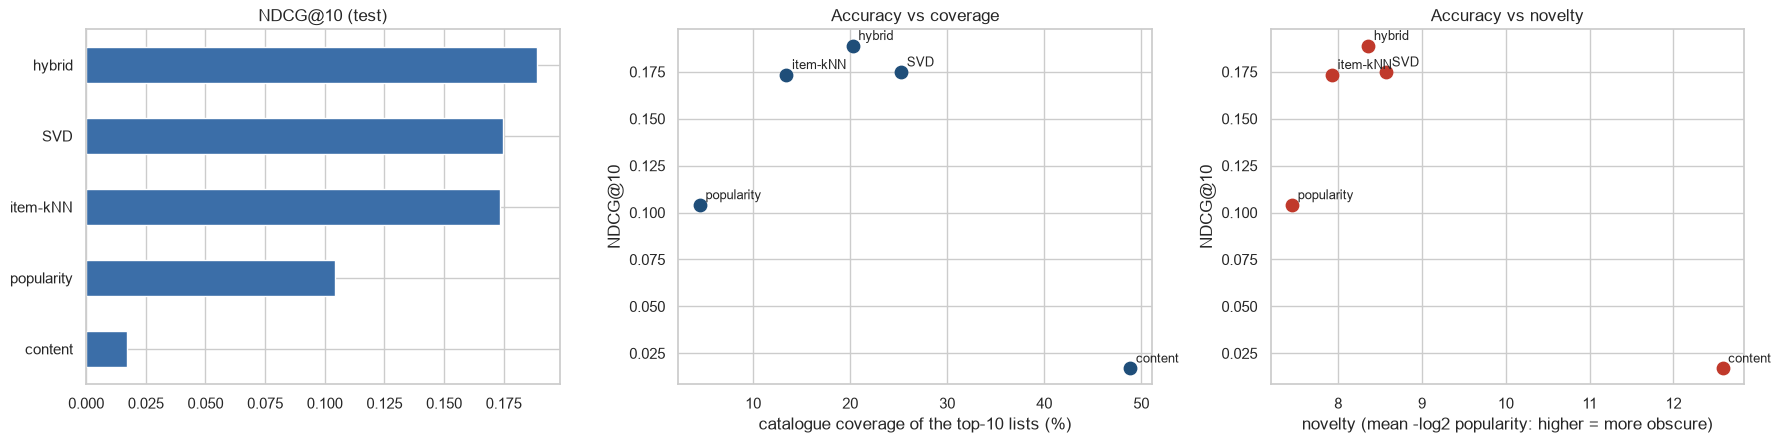

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4.6))
T["ndcg@10"].sort_values().plot.barh(ax=ax[0], color="#3b6ea8"); ax[0].set_title("NDCG@10 (test)")
ax[1].scatter(T["coverage_%"], T["ndcg@10"], s=80, color="#1f4e79")
for n_, row in T.iterrows(): ax[1].annotate(n_, (row["coverage_%"], row["ndcg@10"]), xytext=(4, 4), textcoords="offset points", fontsize=9)
ax[1].set_xlabel("catalogue coverage of the top-10 lists (%)"); ax[1].set_ylabel("NDCG@10"); ax[1].set_title("Accuracy vs coverage")
ax[2].scatter(T["novelty"], T["ndcg@10"], s=80, color="#c0392b")
for n_, row in T.iterrows(): ax[2].annotate(n_, (row["novelty"], row["ndcg@10"]), xytext=(4, 4), textcoords="offset points", fontsize=9)
ax[2].set_xlabel("novelty (mean -log2 popularity: higher = more obscure)"); ax[2].set_ylabel("NDCG@10"); ax[2].set_title("Accuracy vs novelty")
plt.tight_layout(); plt.show()

**Reading it (test: the last 20% of each user's ratings; 907 users).**
* **Hybrid NDCG@10 0.189, SVD 0.175, item-kNN 0.174, popularity 0.104, content 0.017.** The paired bootstrap over users says the hybrid beats SVD by 0.014 (95% interval 0.008 to 0.020) and item-kNN by 0.016 (0.007 to 0.024): **a small but consistent improvement**. SVD and item-kNN are tied (difference 0.001, interval -0.009 to 0.012). The hybrid beats popularity by 0.085 (0.071 to 0.098).
* Absolute level: about 64% of users get at least one liked movie in their top 10 (hit@10 0.64) but the recall@10 is 0.20; most users' later likes are not in any top-10 list, the nature of a sparse, shifting taste.
* **Trade-offs:** the hybrid covers 20% of the catalogue (SVD 25%, item-kNN 13%, popularity 4.5%) and its lists are less varied by genre (diversity 0.60 vs 0.70 for SVD and item-kNN), because the content part pulls recommendations toward similar genres. Content-only recommends the most obscure movies (novelty 12.6, coverage 49%) but almost never a liked one: coverage alone is not quality.

## 6. Cold start: items with almost no ratings, and users with almost no history
* **Cold items:** movies with <= 5 training ratings. Recommend only among them and see which method can rank them.
* **New users:** keep only each user's first 3 training ratings, rebuild the user profile, score on the same test items.

In [8]:
cold = (np.asarray(P_tr.sum(0)).ravel() <= 5); rel_cold = {u: s & set(np.where(cold)[0]) for u, s in rel_te.items()}; rel_cold = {u: s for u, s in rel_cold.items() if s}
print("cold movies:", int(cold.sum()), "| users with a relevant cold movie in test:", len(rel_cold))
cres = {k: evaluate(v, S_tr, rel_cold, items_mask=cold)[0]["ndcg@10"] for k, v in sc.items()}
tr3 = train[train["rank"] < 3]; sc3, P3, S3, _ = score_all(tr3); Z3 = {k: z(v) for k, v in sc3.items()}
sc3["hybrid"] = best_w[0] * Z3["popularity"] + best_w[1] * Z3["content"] + best_w[2] * Z3["item-kNN"] + best_w[3] * Z3["SVD"]
nres = {k: evaluate(v, S3, rel_te)[0]["ndcg@10"] for k, v in sc3.items()}
CS = pd.DataFrame({"NDCG@10 on cold movies": cres, "NDCG@10, users with only 3 ratings": nres, "NDCG@10 normal": T["ndcg@10"]}); print(CS.round(4).to_string())

cold movies: 812 | users with a relevant cold movie in test: 306


            NDCG@10 on cold movies  NDCG@10, users with only 3 ratings  NDCG@10 normal
SVD                         0.0527                              0.0257          0.1749
content                     0.0083                              0.0111          0.0171
hybrid                      0.0568                              0.0347          0.1890
item-kNN                    0.0521                              0.0346          0.1735
popularity                  0.0198                              0.0521          0.1041


**Reading it.**
* **Cold movies (5 or fewer training ratings):** the hybrid reaches 0.057, SVD 0.053 and item-kNN 0.052, far above popularity (0.020) and content-only (0.008). Even five ratings carry a usable signal; the genre-only content model does not help for cold items here, because 19 genres and a decade are too coarse to pick the right obscure film. The reference's content-based part is based on product *text*; MovieLens has only genres, so a richer content representation (plot text, cast) would be needed for a content gain.
* **New users (only 3 ratings known): popularity wins (0.052)**, ahead of the hybrid (0.035) and item-kNN (0.035); SVD scores 0.026. The blend weights were tuned for users with a long history, and for a nearly unknown user the safest list is still "what most people like". A real system would switch strategy by the amount of history.

## 7. Is a lower rating-prediction error (RMSE) the same as better recommendations?
The reference predicts ratings (SVD). I fit a biased matrix factorisation by stochastic gradient descent (the `surprise`-SVD idea) on the training ratings and compare its **RMSE** with simpler predictors, then check what its *ranking* of unseen movies looks like.

In [9]:
mu = train.r.mean(); bu = (train.groupby("u").r.mean() - mu); bi = (train.groupby("i").r.mean() - mu)
def rmse(p, y): return float(np.sqrt(np.mean((p - y) ** 2)))
p_glob = np.full(len(test), mu); p_bias = np.clip(mu + test.u.map(bu).fillna(0) + test.i.map(bi).fillna(0), 1, 5)
K, lr_, reg = 20, 0.007, 0.05; rs = np.random.RandomState(0); Pf = rs.normal(0, .1, (nU, K)); Qf = rs.normal(0, .1, (nI, K)); Bu = np.zeros(nU); Bi = np.zeros(nI)
ua, ia, ra = train.u.to_numpy(), train.i.to_numpy(), train.r.to_numpy(float); hist = []
for ep in range(25):
    for j in rs.permutation(len(ua)):
        u, i = ua[j], ia[j]; e = ra[j] - (mu + Bu[u] + Bi[i] + Pf[u] @ Qf[i]); Bu[u] += lr_ * (e - reg * Bu[u]); Bi[i] += lr_ * (e - reg * Bi[i]); pu = Pf[u].copy(); Pf[u] += lr_ * (e * Qf[i] - reg * Pf[u]); Qf[i] += lr_ * (e * pu - reg * Qf[i])
    if ep % 6 == 5 or ep == 24: hist.append((ep + 1, rmse(np.clip(mu + Bu[test.u] + Bi[test.i] + (Pf[test.u] * Qf[test.i]).sum(1), 1, 5), test.r.to_numpy())))
p_mf = np.clip(mu + Bu[test.u] + Bi[test.i] + (Pf[test.u] * Qf[test.i]).sum(1), 1, 5)
rm = pd.Series({"global mean": rmse(p_glob, test.r), "user + item bias": rmse(p_bias, test.r), "biased matrix factorisation (SGD)": rmse(p_mf, test.r)}); print(rm.round(3).to_string()); print("RMSE by epoch:", [(e, round(v, 3)) for e, v in hist])
Smf = mu + Bu[:, None] + Bi[None, :] + Pf @ Qf.T; m_mf, _ = evaluate(Smf, S_tr, rel_te); print("ranking quality of the rating-predicting model: NDCG@10 = %.4f (popularity %.4f, SVD %.4f, hybrid %.4f)" % (m_mf["ndcg@10"], T.loc["popularity", "ndcg@10"], T.loc["SVD", "ndcg@10"], T.loc["hybrid", "ndcg@10"]))

global mean                          1.208
user + item bias                     1.018
biased matrix factorisation (SGD)    0.976
RMSE by epoch: [(6, 1.008), (12, 0.994), (18, 0.984), (24, 0.976), (25, 0.976)]
ranking quality of the rating-predicting model: NDCG@10 = 0.0524 (popularity 0.1041, SVD 0.1749, hybrid 0.1890)


**Reading it.** The error of predicting a rating falls from 1.21 (global mean) to 1.02 with user and item biases and to **0.976** with the matrix factorisation (the reference's SVD idea): better rating prediction is real, and nothing is wrong with the model. But **its top-10 lists are poor (NDCG@10 0.052), worse than recommending popular movies (0.104)** and far below the SVD and hybrid rankers that were trained for ranking (0.175 and 0.189). A model optimised for rating error is not a model optimised for finding the movies a user will like next: it sees ratings of films the user *chose* to watch, and it ranks films the user never rated by extrapolating, where its predictions are least reliable.

## 8. Recommendations for a person (a sanity check you can read)

In [10]:
liked_titles = ["Star Wars (1977)", "Raiders of the Lost Ark (1981)", "Empire Strikes Back, The (1980)", "Terminator 2: Judgment Day (1991)"]
ids = [int(it.index[it.title == t][0]) for t in liked_titles]
def recommend(ids, k=10, w=best_w):
    p = np.zeros(nI); p[ids] = 1
    prof = p @ CONT; prof /= np.linalg.norm(prof) + 1e-9; c = prof @ CONT.T
    X = P_tr.T.tocsr().astype(float); nrm = np.sqrt(np.asarray(X.multiply(X).sum(1))).ravel() + 1e-9; Sim = (X @ X.T).toarray() / np.outer(nrm, nrm); np.fill_diagonal(Sim, 0); kn = p @ Sim
    uv = svd.transform(sparse.csr_matrix(p[None, :])); sv = svd.inverse_transform(uv)[0]; pv = np.asarray(P_tr.sum(0)).ravel().astype(float)
    zz = lambda v: (v - v.mean()) / (v.std() + 1e-9); s = w[0] * zz(pv) + w[1] * zz(c) + w[2] * zz(kn) + w[3] * zz(sv); s[ids] = -np.inf
    return [it.title[j] for j in np.argsort(-s)[:k]]
print("Liked:", liked_titles); print("Recommended:", *recommend(ids), sep="\n  ")

Liked: ['Star Wars (1977)', 'Raiders of the Lost Ark (1981)', 'Empire Strikes Back, The (1980)', 'Terminator 2: Judgment Day (1991)']
Recommended:
  Return of the Jedi (1983)
  Indiana Jones and the Last Crusade (1989)
  Terminator, The (1984)
  Fugitive, The (1993)
  Princess Bride, The (1987)
  Braveheart (1995)
  Silence of the Lambs, The (1991)
  Die Hard (1988)
  Jurassic Park (1993)
  Aliens (1986)


**Reading it.** For a person who likes *Star Wars*, *Raiders of the Lost Ark*, *The Empire Strikes Back* and *Terminator 2*, the hybrid returns *Return of the Jedi*, *Indiana Jones and the Last Crusade*, *The Terminator*, *Aliens*, *Die Hard*, *Jurassic Park* and *The Fugitive*: sensible action/adventure picks. *The Princess Bride*, *Braveheart* and *The Silence of the Lambs* are looser fits, which is normal for a 100,000-rating data set.

## 9. Save the pieces the app needs

In [11]:
joblib.dump({"svd": svd, "P": P_tr, "content": CONT, "weights": best_w, "titles": it.title.tolist(), "genres": gen, "genre_matrix": it[gen].to_numpy(np.int8), "years": it.year.fillna(0).astype(int).tolist(), "n_items": nI}, "model/hybrid_recommender.joblib")
json.dump({"test": T.round(4).to_dict("index"), "cold": CS.round(4).to_dict("index"), "rmse": rm.round(3).to_dict(), "weights": dict(zip(["popularity", "content", "itemKNN", "SVD"], best_w.tolist()))}, open("model/meta.json", "w"), indent=1)
print(os.listdir("model"))

['hybrid_recommender.joblib', 'meta.json']


## 10. Summary: my approach vs the reference
| | Reference | This notebook |
|---|---|---|
| Data | fashion products table (ratings not verifiable) | MovieLens 100K: 100,000 real ratings, 943 users, 1,682 movies |
| Models | content (TF-IDF text) + `surprise` SVD, blended | popularity, content, item-kNN, SVD, hybrid with weights tuned on a validation slice |
| Evaluation | none | time-based hold-out, NDCG@10 / recall@10 / hit rate, paired bootstrap, coverage, novelty, diversity |
| Result | a blend | hybrid 0.189 > SVD 0.175 = item-kNN 0.174 > popularity 0.104 (NDCG@10; hybrid gain clear but small) |
| Stress tests | none | cold movies (hybrid best), new users (popularity best), rating RMSE vs ranking quality (RMSE-optimal model ranks poorly) |

**What I learned.** (1) Evaluate with a time-based split and ranking metrics, not rating error. (2) A blend of two strong models helped a little, with a clear but small interval; weights must be tuned away from the test set. (3) The best method depends on the situation: popularity wins for new users, collaborative methods for cold items. (4) Coverage, novelty and diversity move in different directions from accuracy.

**Limits.** One 20% time cut; explicit ratings turned into binary "liked" signals; genres only as content; 907 evaluated users (intervals shown are for user sampling only); no online test. **Next step:** richer content (plot text embeddings), implicit-feedback ALS, and a rule that switches to popularity for users with fewer than about 10 ratings.